# TRASHURY — Frozen SigLIP-SO400M + Multi-Seed MLP2 Ensemble

Notebook ini mengadopsi metodologi *Frozen Vision Embedding Probing* untuk **12 kelas sampah TRASHURY**:
1. **Audit Duplikat & Kualitas (`dHash` 8×8):** Mendeteksi gambar korup dan kemiripan lintas split (`train`/`valid`/`test`).
2. **Ekstraksi Embedding Multi-View (`google/siglip-so400m-patch14-384`, `1152`-dim):** Mengambil View 0 asli + 2 view augmentasi untuk data latih.
3. **Diagnostik Embedding (5-Fold OOF Cosine kNN):** Mendeteksi kandidat *label noise* di ruang fitur tanpa menyentuh `valid`/`test`.
4. **Classifier Heads (`Linear`, `MLP`, `MLP2` + `RMSNorm`, `ResMLP`) + Feature Mixup (`alpha=0.4`) + Label Smoothing (`0.1`).**
5. **Multi-Seed & Ensemble Lintas Model (`ens_seed_mlp2` & `ens_lintas_model`):** Menggabungkan 5-seed `MLP2` + 5-seed `ResMLP` + `SVM RBF` + `LogisticRegression` + `Cosine kNN`, diseleksi pada **`valid`**, lalu dievaluasi sekali pada **`test`**.
6. **Ekspor Artefak:** Checkpoint `.pt` (`siglip_api/app.py` compatible) dan head `.onnx`.

## 1. Setup & Instalasi Package

In [1]:
!pip install -q roboflow torch torchvision transformers scikit-learn matplotlib seaborn pillow onnx onnxruntime

In [2]:
import os
import time
import json
import shutil
import random
import zipfile
from getpass import getpass
from collections import Counter, defaultdict

import numpy as np
from PIL import Image, ImageFile
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import transforms
from transformers import SiglipVisionModel, SiglipImageProcessor

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

ImageFile.LOAD_TRUNCATED_IMAGES = True

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Menggunakan device:", device)

Menggunakan device: cuda


## 2. Download & Filter Dataset 12 Kelas (Roboflow)

In [3]:
from roboflow import Roboflow

api_key = os.environ.get("ROBOFLOW_API_KEY") or getpass("Masukkan Roboflow API Key: ")
rf = Roboflow(api_key=api_key)
project = rf.workspace("mirzach89-gmail-com").project("waste-classification-rjo28-2limn")
version = project.version(3)
dataset = version.download("folder")
dataset_path = dataset.location

# 12 kelas target TRASHURY (urut alfabetis sama dengan labels.txt)
kelas_dipakai = sorted([
    'Cardboard Boxes', 'Glass Bottles', 'Glass Shards', 'Jug',
    'Metal Can', 'Paper', 'Paper Bag', 'Paper Cup',
    'Plastic Bottle', 'Plastic Cup', 'Plastic bag', 'food waste'
])
label_to_idx = {k: i for i, k in enumerate(kelas_dipakai)}
idx_to_label = {i: k for i, k in enumerate(kelas_dipakai)}

filtered_path = "/content/dataset_siglip_probe"
if os.path.exists(filtered_path):
    shutil.rmtree(filtered_path)

for split in ['train', 'valid', 'test']:
    for kelas in kelas_dipakai:
        src = os.path.join(dataset_path, split, kelas)
        dst = os.path.join(filtered_path, split, kelas)
        if os.path.exists(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)

for split in ['train', 'valid', 'test']:
    sp = os.path.join(filtered_path, split)
    total = sum(len(os.listdir(os.path.join(sp, k))) for k in os.listdir(sp))
    print(f"{split:5s}: {len(os.listdir(sp))} kelas, {total} gambar")

Masukkan Roboflow API Key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to waste-classification-3 in folder:: 100%|██████████| 2420/2420 [00:00<00:00, 3882.90it/s]


train: 12 kelas, 1556 gambar
valid: 12 kelas, 400 gambar
test : 12 kelas, 207 gambar


## 2.5 Suntikkan & Seimbangkan Data dari `TrashBox` Lintas Split (`70% Train / 15% Valid / 15% Test`)
- Memvalidasi setiap gambar `TrashBox` (`PIL` -> RGB JPEG, ukuran min `50×50`) dan mengecek `dHash` 8×8 agar **tidak ada duplikat** yang bocor antar split.
- Membagi gambar unik secara **stratified proporsional `70% train : 15% valid : 15% test`** untuk menyeimbangkan seluruh split (`train` target $\ge 220$ maks `+100`, `valid` target $\ge 50$ maks `+25`, `test` target $\ge 30$ maks `+20`).

In [4]:
trashbox_dir = "/content/TrashBox"
if not os.path.exists(trashbox_dir):
    !git clone --depth 1 https://github.com/nikhilvenkatkumsetty/TrashBox.git /content/TrashBox

trashbox_sub = os.path.join(trashbox_dir, "TrashBox_train_dataset_subfolders")
if not os.path.exists(trashbox_sub):
    for root, dirs, _ in os.walk(trashbox_dir):
        for d in dirs:
            if "subfolder" in d.lower() and "train" in d.lower():
                trashbox_sub = os.path.join(root, d)
                break
print("Sumber subfolder TrashBox:", trashbox_sub)

def dhash_from_pil(pil_img, hash_size=8):
    gray = pil_img.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
    arr = np.asarray(gray, dtype=np.int16)
    diff = arr[:, 1:] > arr[:, :-1]
    bits = 0
    for bit in diff.flatten():
        bits = (bits << 1) | int(bool(bit))
    return bits

def norm_seg(s):
    return s.lower().replace("_", " ").replace("-", " ").strip()

def map_trashbox_to_trashury(rel_parts):
    parts = [norm_seg(p) for p in rel_parts if p]
    if not parts:
        return None
    top, leaf = parts[0], parts[-1]
    if "paper cup" in leaf:
        return "Paper Cup"
    if "news paper" in leaf or "newspaper" in leaf:
        return "Paper"
    if "plastic" in top:
        if "bag" in leaf:
            return "Plastic bag"
        if "bottle" in leaf:
            return "Plastic Bottle"
        if "cup" in leaf:
            return "Plastic Cup"
        if "container" in leaf:
            return "Jug"
    if "metal" in top and ("beverage can" in leaf or "food grade can" in leaf):
        return "Metal Can"
    if "cardboard" in top:
        return "Cardboard Boxes"
    if "glass" in top:
        return "Glass Bottles"
    return None

# Kumpulkan dHash awal dari seluruh split Roboflow agar TrashBox bebas duplikat lintas split
global_hashes = set()
split_counts_before = {s: {} for s in ['train', 'valid', 'test']}
for s in ['train', 'valid', 'test']:
    for k in kelas_dipakai:
        kdir = os.path.join(filtered_path, s, k)
        fnames = os.listdir(kdir) if os.path.exists(kdir) else []
        split_counts_before[s][k] = len(fnames)
        for fn in fnames:
            try:
                with Image.open(os.path.join(kdir, fn)) as im:
                    global_hashes.add(dhash_from_pil(im))
            except Exception:
                pass

# Kumpulkan kandidat path per kelas dari TrashBox
EXT_VALID = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
tb_kandidat = {k: [] for k in kelas_dipakai}
for root, _, files in os.walk(trashbox_sub):
    rel = os.path.relpath(root, trashbox_sub)
    if rel == ".":
        continue
    target_k = map_trashbox_to_trashury(rel.split(os.sep))
    if target_k in tb_kandidat:
        for fn in sorted(files):
            if os.path.splitext(fn)[1].lower() in EXT_VALID:
                tb_kandidat[target_k].append(os.path.join(root, fn))

TARGET_TR, CAP_TR = 220, 100
TARGET_VA, CAP_VA = 50, 25
TARGET_TE, CAP_TE = 30, 20

print(f"\n{'Kelas':18s} | {'Train (Aw->Ak)':14s} | {'Valid (Aw->Ak)':14s} | {'Test (Aw->Ak)':13s} | {'+TB Tot'}")
print("-" * 78)

for k in kelas_dipakai:
    c_tr = split_counts_before['train'][k]
    c_va = split_counts_before['valid'][k]
    c_te = split_counts_before['test'][k]

    cand_paths = list(tb_kandidat[k])
    random.shuffle(cand_paths)

    if len(cand_paths) == 0:
        print(f"{k:18s} | {c_tr:5d} -> {c_tr:<5d} | {c_va:5d} -> {c_va:<5d} | {c_te:4d} -> {c_te:<5d} | {0:6d}")
        continue

    # Hitung kuota total proporsional 70/15/15 agar setiap split mendapat sebaran i.i.d.
    need_tr = max(0, TARGET_TR - c_tr)
    need_va = max(0, TARGET_VA - c_va)
    need_te = max(0, TARGET_TE - c_te)

    if need_tr == 0 and need_va == 0 and need_te == 0:
        n_total_want = 0
    else:
        est_total = max(need_tr / 0.70, need_va / 0.15, need_te / 0.15)
        n_total_want = min(int(round(est_total)), CAP_TR + CAP_VA + CAP_TE)

    # Filter gambar valid, ukuran >= 50x50, dan bebas duplikat dHash
    accepted = []
    for src_p in cand_paths:
        if len(accepted) >= n_total_want:
            break
        try:
            with Image.open(src_p) as im:
                rgb = im.convert("RGB")
                if min(rgb.size) < 50:
                    continue
                dh = dhash_from_pil(rgb)
                if dh in global_hashes:
                    continue
                global_hashes.add(dh)
                accepted.append(rgb.copy())
        except Exception:
            continue

    n_acc = len(accepted)
    add_tr = min(CAP_TR, int(round(n_acc * 0.70)))
    add_va = min(CAP_VA, int(round(n_acc * 0.15)))
    add_te = min(CAP_TE, max(0, n_acc - add_tr - add_va))
    sisa = n_acc - (add_tr + add_va + add_te)
    if sisa > 0:
        add_tr = min(CAP_TR, add_tr + sisa)

    split_slices = {
        'train': accepted[:add_tr],
        'valid': accepted[add_tr:add_tr + add_va],
        'test':  accepted[add_tr + add_va:add_tr + add_va + add_te],
    }

    for s_name, imgs_list in split_slices.items():
        dst_dir = os.path.join(filtered_path, s_name, k)
        os.makedirs(dst_dir, exist_ok=True)
        for idx_i, rgb_img in enumerate(imgs_list):
            rgb_img.save(os.path.join(dst_dir, f"tb_{s_name}_{idx_i:04d}.jpg"), "JPEG", quality=95)

    n_tr_end = len(os.listdir(os.path.join(filtered_path, 'train', k)))
    n_va_end = len(os.listdir(os.path.join(filtered_path, 'valid', k)))
    n_te_end = len(os.listdir(os.path.join(filtered_path, 'test', k)))
    tot_add = add_tr + add_va + add_te
    print(f"{k:18s} | {c_tr:5d} -> {n_tr_end:<5d} | {c_va:5d} -> {n_va_end:<5d} | {c_te:4d} -> {n_te_end:<5d} | {tot_add:6d}")

for s in ['train', 'valid', 'test']:
    sp = os.path.join(filtered_path, s)
    tot = sum(len(os.listdir(os.path.join(sp, k))) for k in kelas_dipakai)
    print(f"Total {s:5s} sekarang: {tot} gambar")

Cloning into '/content/TrashBox'...
remote: Enumerating objects: 16851, done.
remote: Counting objects: 100% (16851/16851), done.
remote: Compressing objects: 100% (16833/16833), done.
remote: Total 16851 (delta 20), reused 16815 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (16851/16851), 2.41 GiB | 13.28 MiB/s, done.
Resolving deltas: 100% (20/20), done.
Updating files: 100% (28564/28564), done.
Sumber subfolder TrashBox: /content/TrashBox/TrashBox_train_dataset_subfolders

Kelas              | Train (Aw->Ak) | Valid (Aw->Ak) | Test (Aw->Ak) | +TB Tot
------------------------------------------------------------------------------
Cardboard Boxes    |   173 -> 220   |    51 -> 61    |   22 -> 32    |     67


Palette images with Transparency expressed in bytes should be converted to RGBA images


Glass Bottles      |   141 -> 241   |    26 -> 48    |   16 -> 36    |    142
Glass Shards       |    81 -> 81    |    21 -> 21    |   12 -> 12    |      0
Jug                |   110 -> 210   |    30 -> 52    |   15 -> 35    |    142
Metal Can          |   154 -> 220   |    45 -> 59    |   26 -> 40    |     94
Paper              |    75 -> 175   |    22 -> 44    |   12 -> 32    |    142
Paper Bag          |   148 -> 148   |    45 -> 45    |   22 -> 22    |      0
Paper Cup          |   130 -> 220   |    34 -> 53    |   17 -> 37    |    129
Plastic Bottle     |   257 -> 285   |    48 -> 54    |   24 -> 30    |     40
Plastic Cup        |   148 -> 220   |    38 -> 53    |   22 -> 38    |    103
Plastic bag        |    67 -> 167   |    21 -> 43    |    9 -> 29    |    142
food waste         |    72 -> 72    |    19 -> 19    |   10 -> 10    |      0
Total train sekarang: 2259 gambar
Total valid sekarang: 552 gambar
Total test  sekarang: 353 gambar


## 3. Audit Duplikat (`dHash` 8×8) & Kualitas Gambar

In [5]:
def compute_dhash(image_path, hash_size=8):
    with Image.open(image_path) as img:
        gray = img.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
        arr = np.asarray(gray, dtype=np.int16)
        diff = arr[:, 1:] > arr[:, :-1]
        bits = 0
        for bit in diff.flatten():
            bits = (bits << 1) | int(bool(bit))
        return bits

def collect_split_records(split_name):
    records = []
    split_dir = os.path.join(filtered_path, split_name)
    for kelas in kelas_dipakai:
        kdir = os.path.join(split_dir, kelas)
        if not os.path.exists(kdir):
            continue
        for fname in sorted(os.listdir(kdir)):
            fpath = os.path.join(kdir, fname)
            try:
                with Image.open(fpath) as im:
                    im.verify()
                dh = compute_dhash(fpath)
                records.append({"path": fpath, "kelas": kelas, "y": label_to_idx[kelas], "dhash": dh, "split": split_name})
            except Exception as e:
                print(f"[CORRUPT] Dilewati {fpath}: {e}")
    return records

train_recs = collect_split_records("train")
val_recs   = collect_split_records("valid")
test_recs  = collect_split_records("test")

# Cek exact dHash duplikat di dalam train maupun lintas split
eval_hashes = {r["dhash"] for r in val_recs + test_recs}
cross_split_dups = [r for r in train_recs if r["dhash"] in eval_hashes]

seen_train = set()
intra_train_dups = []
for r in train_recs:
    if r["dhash"] in seen_train:
        intra_train_dups.append(r)
    seen_train.add(r["dhash"])

print(f"Jumlah gambar terbaca   -> train: {len(train_recs)}, valid: {len(val_recs)}, test: {len(test_recs)}")
print(f"Duplikat exact dHash    -> intra-train: {len(intra_train_dups)}, cross-split (train∩eval): {len(cross_split_dups)}")

Jumlah gambar terbaca   -> train: 2259, valid: 552, test: 353
Duplikat exact dHash    -> intra-train: 119, cross-split (train∩eval): 109


## 4. Ekstraksi Embedding Multi-View `google/siglip-so400m-patch14-384` (`1152`-dim)
Mengekstrak **View 0 (Asli `384×384` Bicubic)** untuk `train`/`valid`/`test` dan **2 View Augmentasi** tambahan untuk `train`, lalu menyimpan ke `/content/siglip_so400m_trashury12_tb.npz`.

In [6]:
MODEL_ID = "google/siglip-so400m-patch14-384"
IMAGE_SIZE = 384
BATCH_SIZE = 32
N_AUG_VIEWS = 2
EMB_CACHE = "/content/siglip_so400m_trashury12_tb.npz"

if os.path.exists(EMB_CACHE):
    print(f"Memuat cache embedding dari {EMB_CACHE}...")
    data_npz = np.load(EMB_CACHE, allow_pickle=False)
    train_emb_all = data_npz["train_emb"]
    train_y_all = data_npz["train_y"]
    train_orig_idx_all = data_npz["train_orig_idx"]
    train_view_all = data_npz["train_view"]
    val_emb = data_npz["val_emb"]
    val_y = data_npz["val_y"]
    test_emb = data_npz["test_emb"]
    test_y = data_npz["test_y"]
else:
    dtype = torch.float16 if device.type == "cuda" else torch.float32
    print(f"Memuat {MODEL_ID} ({dtype})...")
    proc = SiglipImageProcessor.from_pretrained(MODEL_ID)
    vision_model = SiglipVisionModel.from_pretrained(MODEL_ID).to(device=device, dtype=dtype).eval()

    tf_view0 = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize(mean=proc.image_mean, std=proc.image_std),
    ])
    tf_aug = transforms.Compose([
        transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0), interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.04),
        transforms.ToTensor(),
        transforms.Normalize(mean=proc.image_mean, std=proc.image_std),
    ])

    @torch.inference_mode()
    def extract_view(records, tf, desc=""):
        embs = []
        t0 = time.time()
        for i in range(0, len(records), BATCH_SIZE):
            batch_recs = records[i:i+BATCH_SIZE]
            imgs = torch.stack([tf(Image.open(r["path"]).convert("RGB")) for r in batch_recs])
            imgs = imgs.to(device=device, dtype=dtype)
            out = vision_model(pixel_values=imgs)
            embs.append(out.pooler_output.float().cpu().numpy())
        arr = np.concatenate(embs, axis=0)
        print(f"  Selesai ekstraksi {desc}: shape={arr.shape} ({time.time()-t0:.1f}s)")
        return arr

    tr_v0 = extract_view(train_recs, tf_view0, "train view0")
    tr_embs = [tr_v0]
    tr_ys = [np.array([r["y"] for r in train_recs], dtype=np.int64)]
    tr_idxs = [np.arange(len(train_recs), dtype=np.int64)]
    tr_views = [np.zeros(len(train_recs), dtype=np.int64)]

    for v in range(1, N_AUG_VIEWS + 1):
        seed_everything(42 + v)
        tr_va = extract_view(train_recs, tf_aug, f"train aug{v}")
        tr_embs.append(tr_va)
        tr_ys.append(tr_ys[0])
        tr_idxs.append(tr_idxs[0])
        tr_views.append(np.full(len(train_recs), v, dtype=np.int64))

    train_emb_all = np.concatenate(tr_embs, axis=0)
    train_y_all = np.concatenate(tr_ys, axis=0)
    train_orig_idx_all = np.concatenate(tr_idxs, axis=0)
    train_view_all = np.concatenate(tr_views, axis=0)

    val_emb = extract_view(val_recs, tf_view0, "valid view0")
    val_y = np.array([r["y"] for r in val_recs], dtype=np.int64)

    test_emb = extract_view(test_recs, tf_view0, "test view0")
    test_y = np.array([r["y"] for r in test_recs], dtype=np.int64)

    np.savez_compressed(
        EMB_CACHE,
        train_emb=train_emb_all, train_y=train_y_all,
        train_orig_idx=train_orig_idx_all, train_view=train_view_all,
        val_emb=val_emb, val_y=val_y,
        test_emb=test_emb, test_y=test_y,
    )
    del vision_model
    torch.cuda.empty_cache()

v0_mask = (train_view_all == 0)
train_emb_v0 = train_emb_all[v0_mask]
train_y_v0 = train_y_all[v0_mask]
print(f"Siap! Embedding dim={train_emb_v0.shape[1]} | Train Views={len(train_emb_all)} | Val={len(val_emb)} | Test={len(test_emb)}")

Memuat google/siglip-so400m-patch14-384 (torch.float16)...


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/576 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.51GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/448 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-so400m-patch14-384
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...26}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.m

  Selesai ekstraksi train view0: shape=(2259, 1152) (121.9s)
  Selesai ekstraksi train aug1: shape=(2259, 1152) (160.0s)
  Selesai ekstraksi train aug2: shape=(2259, 1152) (162.1s)
  Selesai ekstraksi valid view0: shape=(552, 1152) (32.0s)
  Selesai ekstraksi test view0: shape=(353, 1152) (20.4s)
Siap! Embedding dim=1152 | Train Views=6777 | Val=552 | Test=353


## 5. Diagnostik Embedding & Deteksi *Label Noise* (5-Fold OOF Cosine kNN)

In [7]:
def l2_norm_np(x):
    norms = np.linalg.norm(x, axis=-1, keepdims=True)
    return x / np.clip(norms, 1e-12, None)

def cosine_knn_predict_proba(X_train_norm, y_train, X_query_norm, num_classes=12, k=15, temp=0.05):
    sims = X_query_norm @ X_train_norm.T
    top_idx = np.argpartition(-sims, kth=min(k, sims.shape[1]-1), axis=1)[:, :k]
    top_sims = np.take_along_axis(sims, top_idx, axis=1)
    weights = np.exp((top_sims - np.max(top_sims, axis=1, keepdims=True)) / temp)
    probs = np.zeros((X_query_norm.shape[0], num_classes), dtype=np.float32)
    top_labels = y_train[top_idx]
    for c in range(num_classes):
        probs[:, c] = np.sum(weights * (top_labels == c), axis=1)
    probs /= np.clip(probs.sum(axis=1, keepdims=True), 1e-12, None)
    return probs

X_v0_norm = l2_norm_np(train_emb_v0)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = np.zeros((len(train_emb_v0), len(kelas_dipakai)), dtype=np.float32)

for tr_i, va_i in skf.split(X_v0_norm, train_y_v0):
    oof_probs[va_i] = cosine_knn_predict_proba(X_v0_norm[tr_i], train_y_v0[tr_i], X_v0_norm[va_i], len(kelas_dipakai), k=15)

oof_pred = np.argmax(oof_probs, axis=1)
oof_conf = np.max(oof_probs, axis=1)
oof_acc = accuracy_score(train_y_v0, oof_pred)
oof_f1 = f1_score(train_y_v0, oof_pred, average="macro")
print(f"OOF Cosine kNN (Train View 0) -> Acc: {oof_acc*100:.2f}% | Macro F1: {oof_f1:.4f}")

# Kandidat label noise: OOF yakin (>0.85) tapi berbeda dari label folder
noise_idx = np.where((oof_pred != train_y_v0) & (oof_conf >= 0.85))[0]
noise_idx = noise_idx[np.argsort(-oof_conf[noise_idx])]
print(f"Terdeteksi {len(noise_idx)} kandidat label noise kuat (conf >= 0.85). Top-10:")
for idx in noise_idx[:10]:
    print(f"  - {os.path.basename(train_recs[idx]['path'])[:40]:40s} | Asli: {idx_to_label[train_y_v0[idx]]:15s} -> OOF Saran: {idx_to_label[oof_pred[idx]]:15s} ({oof_conf[idx]:.2f})")

OOF Cosine kNN (Train View 0) -> Acc: 92.39% | Macro F1: 0.9321
Terdeteksi 10 kandidat label noise kuat (conf >= 0.85). Top-10:
  - tb_train_0080.jpg                        | Asli: Glass Bottles   -> OOF Saran: Plastic Bottle  (1.00)
  - 23134682_302215730263452_351624638_o_jpg | Asli: Plastic Cup     -> OOF Saran: Paper Cup       (1.00)
  - NKXHXPWTWNAYVNQHW5B3FZQPSU_jpeg.rf.40f3f | Asli: Plastic bag     -> OOF Saran: Plastic Bottle  (1.00)
  - tb_train_0090.jpg                        | Asli: Plastic bag     -> OOF Saran: Paper Bag       (0.96)
  - tb_train_0023.jpg                        | Asli: Plastic Cup     -> OOF Saran: Paper Cup       (0.94)
  - 53e71b30-887e-467e-af85-7a5ee906beaf_1-c | Asli: Paper Cup       -> OOF Saran: Plastic Cup     (0.93)
  - tb_train_0032.jpg                        | Asli: Cardboard Boxes -> OOF Saran: Paper           (0.91)
  - tb_train_0016.jpg                        | Asli: Glass Bottles   -> OOF Saran: Plastic Bottle  (0.88)
  - The-Truth-About-Plas

## 6. Arsitektur Classifier Heads (`Linear`, `MLP`, `MLP2` + `RMSNorm`, `ResMLP`) & Training dengan Mixup
- Standardisasi `(x - mu) / sd` dihitung **murni dari `train` View 0**.
- Menggunakan **Feature-Space Mixup (`alpha=0.4`)**, **Label Smoothing (`0.1`)**, **Class Weights**, dan **Multi-Seed (`42..46`)** untuk `mlp2` dan `resmlp`.

In [8]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

class ResMLPBlock(nn.Module):
    def __init__(self, in_dim: int, hid: int, num_classes: int, dropout: float = 0.3):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(in_dim, hid), RMSNorm(hid), nn.GELU(), nn.Dropout(dropout))
        self.res  = nn.Sequential(nn.Linear(hid, hid), RMSNorm(hid), nn.GELU(), nn.Dropout(dropout), nn.Linear(hid, hid))
        self.norm = RMSNorm(hid)
        self.head = nn.Linear(hid, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.proj(x)
        h = self.norm(h + self.res(h))
        return self.head(h)

def build_head(head_type: str, in_dim: int, num_classes: int, dropout: float = 0.3, act: str = "gelu") -> nn.Module:
    act_layer = lambda: nn.SiLU() if act == "silu" else nn.GELU()
    if head_type == "linear":
        return nn.Linear(in_dim, num_classes)
    if head_type == "mlp":
        h = in_dim // 2
        return nn.Sequential(nn.Linear(in_dim, h), act_layer(), nn.Dropout(dropout), nn.Linear(h, num_classes))
    if head_type == "mlp2":
        return nn.Sequential(
            nn.Linear(in_dim, 512), RMSNorm(512), act_layer(), nn.Dropout(dropout),
            nn.Linear(512, 128), RMSNorm(128), act_layer(), nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )
    if head_type == "resmlp":
        return ResMLPBlock(in_dim, 512, num_classes, dropout)
    raise ValueError(f"Unsupported head_type: {head_type}")

# Hitung mean/std strictly pada Train View 0 (zero data leakage)
mu_np = train_emb_v0.mean(axis=0, keepdims=True).astype(np.float32)
sd_np = np.clip(train_emb_v0.std(axis=0, keepdims=True), 1e-6, None).astype(np.float32)

X_tr_std = (train_emb_all - mu_np) / sd_np
X_va_std = (val_emb - mu_np) / sd_np
X_te_std = (test_emb - mu_np) / sd_np

mu_t = torch.tensor(mu_np.squeeze(0), dtype=torch.float32)
sd_t = torch.tensor(sd_np.squeeze(0), dtype=torch.float32)

num_classes = len(kelas_dipakai)
cnt = Counter(train_y_v0.tolist())
cw = torch.tensor([len(train_y_v0) / (num_classes * cnt[c]) for c in range(num_classes)], dtype=torch.float32).to(device)
cw = cw / cw.mean()

def train_probe_head(head_type="mlp2", seed=42, epochs=80, batch_size=128, lr=1e-3, mixup_alpha=0.4, label_smoothing=0.1):
    seed_everything(seed)
    in_dim = X_tr_std.shape[1]
    model = build_head(head_type, in_dim, num_classes, dropout=0.3, act="gelu").to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    ds_tr = TensorDataset(torch.tensor(X_tr_std, dtype=torch.float32), torch.tensor(train_y_all, dtype=torch.long))
    dl_tr = DataLoader(ds_tr, batch_size=batch_size, shuffle=True)
    X_va_t = torch.tensor(X_va_std, dtype=torch.float32, device=device)

    best_f1 = -1.0
    best_state = None
    for ep in range(epochs):
        model.train()
        for xb, yb in dl_tr:
            xb, yb = xb.to(device), yb.to(device)
            if mixup_alpha > 0 and xb.size(0) > 1:
                lam = np.random.beta(mixup_alpha, mixup_alpha)
                perm = torch.randperm(xb.size(0), device=device)
                x_mix = lam * xb + (1.0 - lam) * xb[perm]
                logits = model(x_mix)
                loss_a = F.cross_entropy(logits, yb, weight=cw, label_smoothing=label_smoothing)
                loss_b = F.cross_entropy(logits, yb[perm], weight=cw, label_smoothing=label_smoothing)
                loss = lam * loss_a + (1.0 - lam) * loss_b
            else:
                loss = F.cross_entropy(model(xb), yb, weight=cw, label_smoothing=label_smoothing)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        scheduler.step()

        model.eval()
        with torch.inference_mode():
            val_logits = model(X_va_t)
            val_preds = torch.argmax(val_logits, dim=-1).cpu().numpy()
            val_f1 = f1_score(val_y, val_preds, average="macro")
            if val_f1 > best_f1:
                best_f1 = val_f1
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    ckpt_dir = "/content/siglip_heads_v1"
    os.makedirs(ckpt_dir, exist_ok=True)
    ckpt_path = f"{ckpt_dir}/best_head_{head_type}_s{seed}.pt"
    torch.save({
        "head_type": head_type,
        "in_dim": in_dim,
        "num_classes": num_classes,
        "dropout": 0.3,
        "act": "gelu",
        "state_dict": best_state,
        "input_norm": {"mode": "standardize", "mu": mu_t, "sd": sd_t},
        "label_to_idx": label_to_idx,
    }, ckpt_path)
    return model, best_f1, ckpt_path

@torch.inference_mode()
def predict_probs_torch(model, X_std):
    logits = model(torch.tensor(X_std, dtype=torch.float32, device=device))
    return torch.softmax(logits, dim=-1).cpu().numpy()

results_val = {}
ckpt_paths = {}

# 1. Single seed comparison
for htype in ["linear", "mlp", "mlp2", "resmlp"]:
    m, vf1, cpath = train_probe_head(htype, seed=42)
    p_val = predict_probs_torch(m, X_va_std)
    p_test = predict_probs_torch(m, X_te_std)
    results_val[htype] = {"val_probs": p_val, "test_probs": p_test, "val_f1": vf1}
    ckpt_paths[f"{htype}_s42"] = (m, cpath)
    print(f"Head {htype:8s} (s42) -> Val Macro F1: {vf1:.4f} | Val Acc: {accuracy_score(val_y, p_val.argmax(1))*100:.2f}%")

# 2. Multi-seed 42..46 untuk mlp2 & resmlp
SEEDS = [42, 43, 44, 45, 46]
mlp2_val_list, mlp2_test_list = [], []
resmlp_val_list, resmlp_test_list = [], []

for s in SEEDS:
    if s == 42:
        m2, _ = ckpt_paths["mlp2_s42"]
        mr, _ = ckpt_paths["resmlp_s42"]
    else:
        m2, _, cp2 = train_probe_head("mlp2", seed=s)
        mr, _, cpr = train_probe_head("resmlp", seed=s)
        ckpt_paths[f"mlp2_s{s}"] = (m2, cp2)
        ckpt_paths[f"resmlp_s{s}"] = (mr, cpr)
    mlp2_val_list.append(predict_probs_torch(m2, X_va_std))
    mlp2_test_list.append(predict_probs_torch(m2, X_te_std))
    resmlp_val_list.append(predict_probs_torch(mr, X_va_std))
    resmlp_test_list.append(predict_probs_torch(mr, X_te_std))

results_val["ens_seed_mlp2"] = {
    "val_probs": np.mean(mlp2_val_list, axis=0),
    "test_probs": np.mean(mlp2_test_list, axis=0),
}
results_val["ens_seed_resmlp"] = {
    "val_probs": np.mean(resmlp_val_list, axis=0),
    "test_probs": np.mean(resmlp_test_list, axis=0),
}

Head linear   (s42) -> Val Macro F1: 0.9457 | Val Acc: 94.57%
Head mlp      (s42) -> Val Macro F1: 0.9632 | Val Acc: 96.38%
Head mlp2     (s42) -> Val Macro F1: 0.9617 | Val Acc: 96.01%
Head resmlp   (s42) -> Val Macro F1: 0.9661 | Val Acc: 96.56%


## 7. Ensemble Lintas Model (`ens_lintas_model`) & Evaluasi Final (Valid $\to$ Test Sekali)

=== Seleksi Model Berdasarkan Validation Macro F1 ===
Model                | Val Acc    | Val Macro F1
------------------------------------------------
linear               |    94.57%  |     0.9457
mlp                  |    96.38%  |     0.9632
mlp2                 |    96.01%  |     0.9617
resmlp               |    96.56%  |     0.9661
ens_seed_mlp2        |    96.20%  |     0.9642
ens_seed_resmlp      |    96.38%  |     0.9657
logreg               |    94.38%  |     0.9450
svm_rbf              |    95.65%  |     0.9598
knn_cosine           |    93.30%  |     0.9365
ens_lintas_model     |    96.01%  |     0.9625

Model terpilih (strictly dari Val): resmlp (Val Macro F1 = 0.9661)

=== HASIL FINAL TEST SET ===
Model Terpilih        : resmlp
Test Accuracy         : 96.03%
Test Macro F1         : 0.9644
EfficientNet-B2 (v3)  : 88.89% (Test TTA) | Macro F1: 0.8900
Selisih vs EffNet-B2  : +7.14%

                 precision    recall  f1-score   support

Cardboard Boxes       1.00      1.00

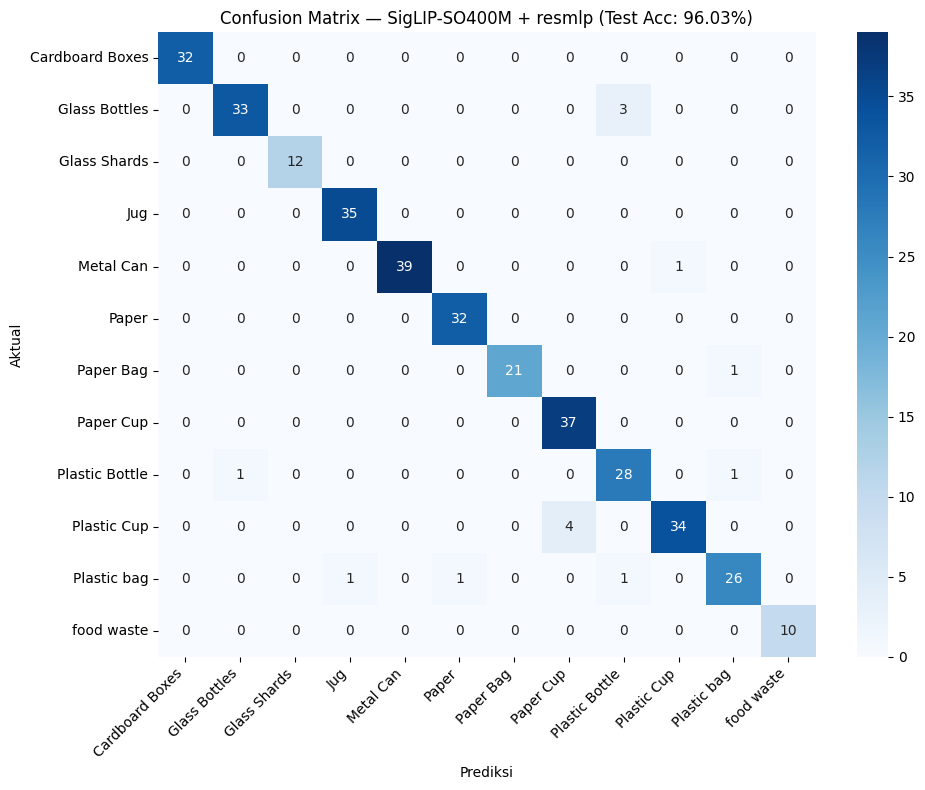

In [9]:
# Model klasik di atas embedding View 0 (SVM RBF, Logistic Regression, Cosine kNN)
X_tr_v0_std = (train_emb_v0 - mu_np) / sd_np

logreg = LogisticRegression(C=2.0, class_weight="balanced", max_iter=1000, random_state=42)
logreg.fit(X_tr_v0_std, train_y_v0)
results_val["logreg"] = {
    "val_probs": logreg.predict_proba(X_va_std),
    "test_probs": logreg.predict_proba(X_te_std),
}

svm_rbf = SVC(C=3.0, kernel="rbf", probability=True, class_weight="balanced", random_state=42)
svm_rbf.fit(X_tr_v0_std, train_y_v0)
results_val["svm_rbf"] = {
    "val_probs": svm_rbf.predict_proba(X_va_std),
    "test_probs": svm_rbf.predict_proba(X_te_std),
}

X_va_norm = l2_norm_np(val_emb)
X_te_norm = l2_norm_np(test_emb)
results_val["knn_cosine"] = {
    "val_probs": cosine_knn_predict_proba(X_v0_norm, train_y_v0, X_va_norm, num_classes, k=15),
    "test_probs": cosine_knn_predict_proba(X_v0_norm, train_y_v0, X_te_norm, num_classes, k=15),
}

# Ensemble Lintas Model: ens_seed_mlp2 + ens_seed_resmlp + svm_rbf + logreg + knn_cosine
komponen_lintas = ["ens_seed_mlp2", "ens_seed_resmlp", "svm_rbf", "logreg", "knn_cosine"]
results_val["ens_lintas_model"] = {
    "val_probs": np.mean([results_val[k]["val_probs"] for k in komponen_lintas], axis=0),
    "test_probs": np.mean([results_val[k]["test_probs"] for k in komponen_lintas], axis=0),
}

print("=== Seleksi Model Berdasarkan Validation Macro F1 ===")
print(f"{'Model':20s} | {'Val Acc':10s} | {'Val Macro F1':12s}")
print("-" * 48)

best_name = None
best_val_f1 = -1.0
for name, pack in results_val.items():
    vp = pack["val_probs"].argmax(axis=1)
    vacc = accuracy_score(val_y, vp)
    vf1 = f1_score(val_y, vp, average="macro")
    pack["val_f1_final"] = vf1
    print(f"{name:20s} | {vacc*100:8.2f}%  | {vf1:10.4f}")
    if vf1 > best_val_f1:
        best_val_f1 = vf1
        best_name = name

print(f"\nModel terpilih (strictly dari Val): {best_name} (Val Macro F1 = {best_val_f1:.4f})")

# Evaluasi TEST SET sekali untuk model terpilih
te_probs = results_val[best_name]["test_probs"]
te_pred = te_probs.argmax(axis=1)
te_acc = accuracy_score(test_y, te_pred)
te_f1 = f1_score(test_y, te_pred, average="macro")

print("\n=== HASIL FINAL TEST SET ===")
print(f"Model Terpilih        : {best_name}")
print(f"Test Accuracy         : {te_acc*100:.2f}%")
print(f"Test Macro F1         : {te_f1:.4f}")
print(f"EfficientNet-B2 (v3)  : 88.89% (Test TTA) | Macro F1: 0.8900")
print(f"Selisih vs EffNet-B2  : {(te_acc - 0.8889)*100:+.2f}%")
print()
print(classification_report(test_y, te_pred, target_names=kelas_dipakai))

cm = confusion_matrix(test_y, te_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=kelas_dipakai, yticklabels=kelas_dipakai, cmap='Blues')
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title(f"Confusion Matrix — SigLIP-SO400M + {best_name} (Test Acc: {te_acc*100:.2f}%)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 8. Ekspor Artefak Head (`.pt` Multi-Seed & `.onnx`)

In [10]:
import onnxruntime as ort
from google.colab import files

# 1. Simpan ensemble head MLP2 (5 seed) menjadi 1 modul PyTorch untuk ekspor ONNX
class EnsembleMLP2WithNorm(nn.Module):
    def __init__(self, heads, mu, sd):
        super().__init__()
        self.heads = nn.ModuleList(heads)
        self.register_buffer("mu", mu)
        self.register_buffer("sd", sd)

    def forward(self, emb: torch.Tensor) -> torch.Tensor:
        x = (emb - self.mu) / self.sd
        probs = [torch.softmax(h(x), dim=-1) for h in self.heads]
        return torch.stack(probs, dim=0).mean(dim=0)

mlp2_models = [ckpt_paths[f"mlp2_s{s}"][0].cpu().eval() for s in SEEDS]
ens_export = EnsembleMLP2WithNorm(mlp2_models, mu_t, sd_t).eval()

head_onnx_path = "siglip_ens_mlp2_head.onnx"
dummy_emb = torch.randn(1, 1152)
torch.onnx.export(
    ens_export, dummy_emb, head_onnx_path,
    export_params=True, opset_version=14, do_constant_folding=True,
    input_names=["embedding"], output_names=["probabilities"],
    dynamic_axes={"embedding": {0: "batch_size"}, "probabilities": {0: "batch_size"}},
    dynamo=False,
)

sess = ort.InferenceSession(head_onnx_path)
out_check = sess.run(None, {"embedding": np.random.randn(1, 1152).astype(np.float32)})[0]
print(f"✅ Head ONNX sukses: {head_onnx_path} ({os.path.getsize(head_onnx_path)/(1024*1024):.2f} MB) | shape={out_check.shape}")

# 2. Bungkus seluruh checkpoint .pt multi-seed ke dalam arsip zip
zip_path = "siglip_heads_checkpoints.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for s in SEEDS:
        _, cp = ckpt_paths[f"mlp2_s{s}"]
        zf.write(cp, arcname=os.path.basename(cp))
print(f"✅ Checkpoints .pt dibungkus ke: {zip_path}")

files.download(head_onnx_path)
files.download(zip_path)

You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html


✅ Head ONNX sukses: siglip_ens_mlp2_head.onnx (12.59 MB) | shape=(1, 12)
✅ Checkpoints .pt dibungkus ke: siglip_heads_checkpoints.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>